In [2]:
import numpy as np
import matplotlib.pyplot as plt
from pwr_two_point_plant_v2 import *

In [3]:
plant = Plant()
print(f"{plant.n} states, {plant.m} inputs")

53 states, 8 inputs


In [4]:
x0, u0, residual = trim(plant, 1.0)      # 1.0 = 100 % power
print(f"residual: {residual:.2e}")

sig = plant.signals(x0)
for k in ("Pn", "DI", "Tavg", "Thot", "Tcold", "ps"):
    print(f"  {k:6s} {sig[k]:10.4f}")

residual: 5.29e-13
  Pn         1.0000
  DI         0.0000
  Tavg     315.9221
  Thot     327.2997
  Tcold    296.9595
  ps         7.2800


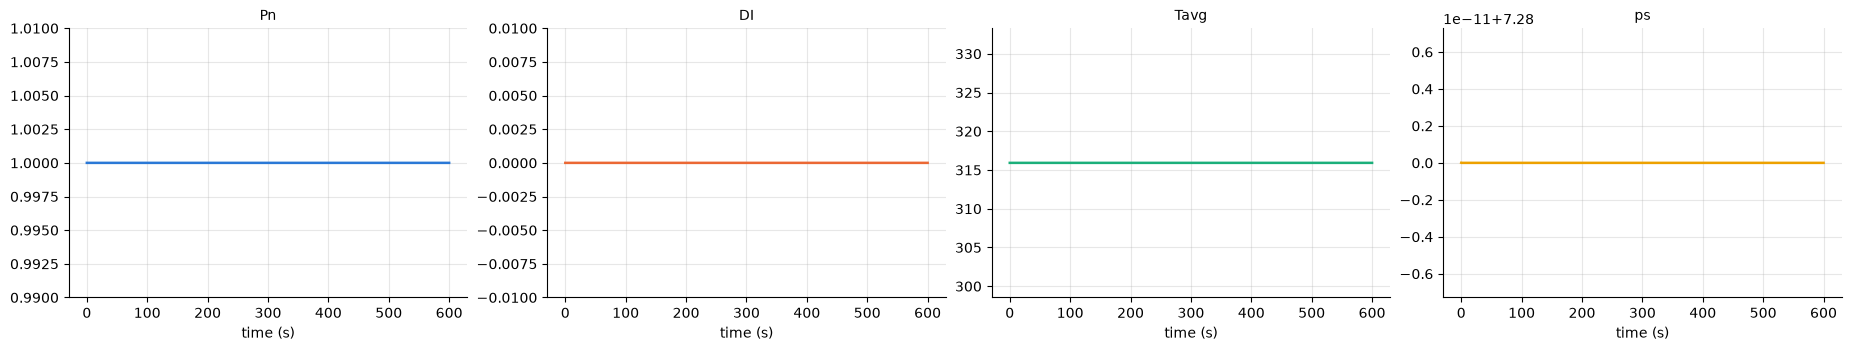

In [5]:
res = ClosedLoop(plant, [], x0=x0, u0=u0).run(600)     # 600 seconds

axs = res.plot(["Pn", "DI", "Tavg", "ps"], subplots=True)
axs[0].set_ylim(0.99, 1.01)
axs[1].set_ylim(-0.01, 0.01)
plt.show()


In [6]:
res.df[["t", "Pn", "DI", "ps", "u_utg"]].tail(3) # tail gets the last 3 entries of the dataframe. Opposite to .head()


,t,Pn,DI,ps,u_utg
1497,599.199466,1.0,-2.220446e-16,7.28,0.999631
1498,599.599733,1.0,-2.220446e-16,7.28,0.999631
1499,600.000000,1.0,-3.330669e-16,7.28,0.999631


In [7]:
print(U_NAMES)          # ['vrod_M', 'vrod_AO', 'utg', 'iheat', 'mdot_spr', 'Pdem', 'T_fw']
print(IU["utg"])        # 2        <- 'utg' is the third slot
print(u0)               # [0.  0.  0.99963  0.  0.  0.99996  232.2]
print(u0[IU["utg"]])    # 0.99963  <- the valve, at the trim point


['vrod_M', 'vrod_AO', 'utg', 'iheat', 'mdot_spr', 'Pdem', 'T_fw', 'mdot_sur']
2
[  0.           0.           0.99963087   0.           0.
   0.99995625 232.2          0.        ]
0.9996308697676789


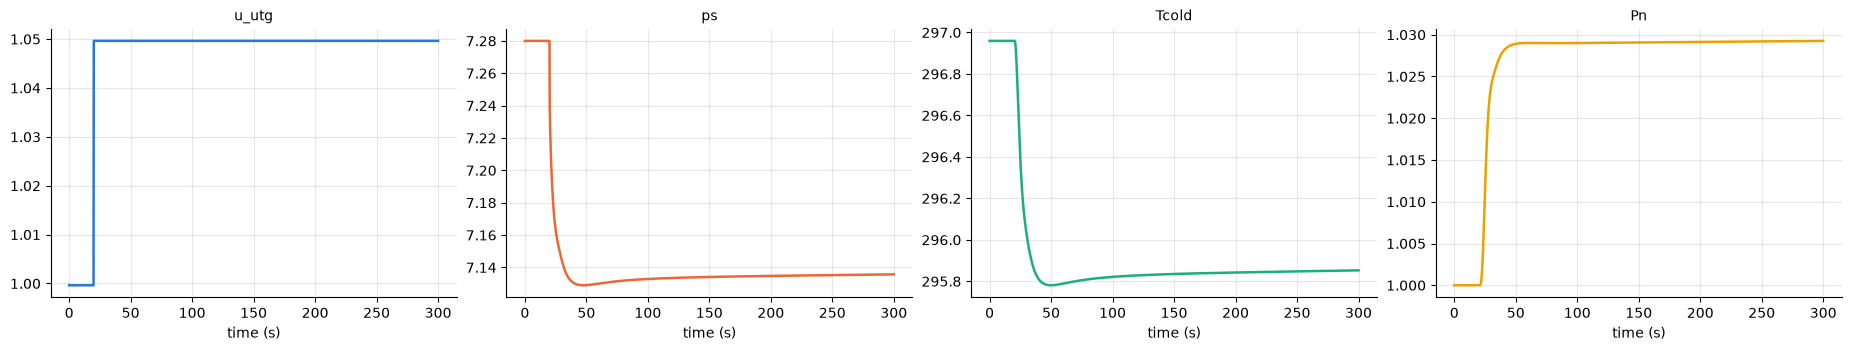

In [8]:
base = u0[IU["utg"]]      # the trimmed valve position, 0.99963 (not 1.0)

loop = ClosedLoop(
    plant,
    [Manual("utg", lambda t, sig: base + (0.05 if t > 20 else 0))],
    x0=x0, u0=u0,
)
res = loop.run(300)

res.plot(["u_utg", "ps", "Tcold", "Pn"], subplots=True)
plt.show()


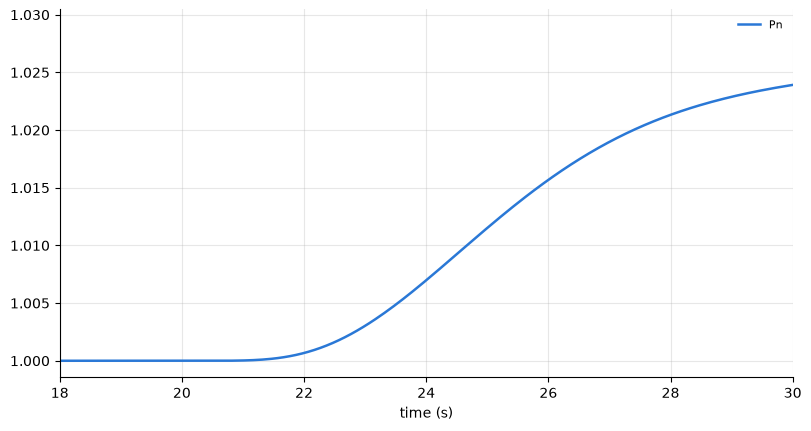

In [9]:
res = loop.run(60, n_out=1200)
ax = res.plot(["Pn"])
ax.set_xlim(18, 30)
plt.show()


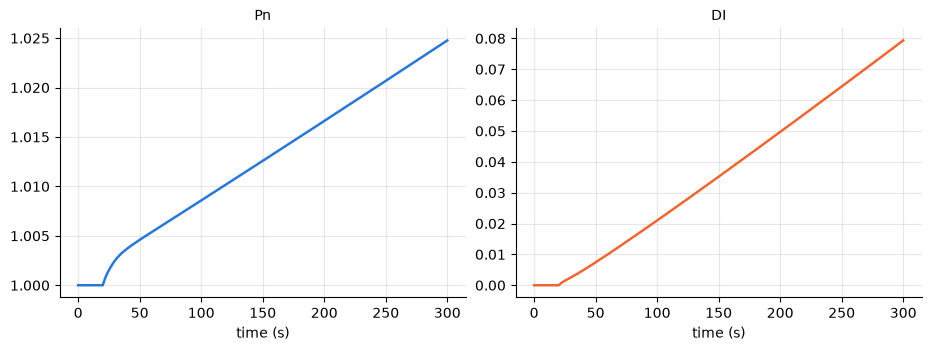

In [10]:
loop = ClosedLoop(
    plant,
    [Manual("vrod_M", lambda t, sig: 5.0 if t > 20 else 0.0)],
    x0=x0, u0=u0,
)
res = loop.run(300)
res.plot(["Pn", "DI"], subplots=True)
plt.show()


In [11]:
class HoldPower(Controller):
    name = "hold_power"

    def update(self, t, sig, xc, u, ctx):
        error = ctx.demand(t) - sig["Pn"]              # where we want - where we are
        speed = float(np.clip(3000.0 * error, -72.0, 72.0))
        u[IU["vrod_M"]]  += speed                      # note +=
        u[IU["vrod_AO"]] += speed
        return EMPTY                                   # no internal state


In [12]:
loop = ClosedLoop(
    plant,
    [HoldPower(),
     Manual("utg", lambda t, sig: base + (0.05 if t > 20 else 0))],
    demand=lambda t: 1.0,          # hold 100 % power
    x0=x0, u0=u0,
)
res = loop.run(300)


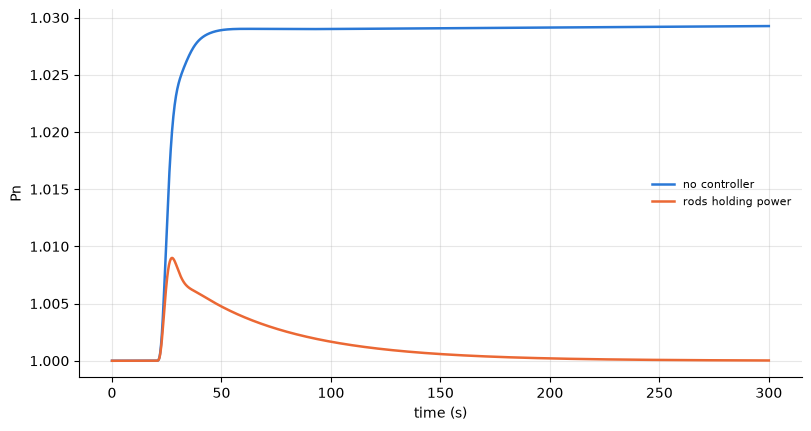

In [13]:
ol = ClosedLoop(plant,
                [Manual("utg", lambda t, sig: base + (0.05 if t > 20 else 0))],
                x0=x0, u0=u0).run(300)

ax = ol.plot(["Pn"], label="no controller")
res.plot(["Pn"], ax=ax, label="rods holding power")
ax.set_ylabel("Pn")
plt.show()


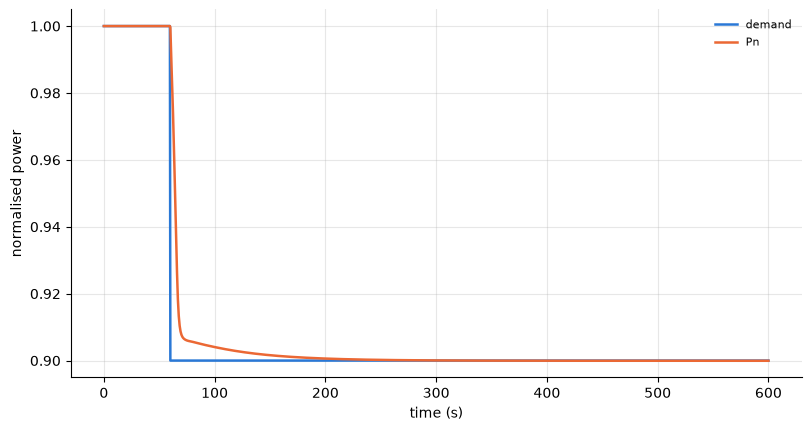

In [16]:
demand = step(1.0, 0.9, t_step=60.0)      # drop to 90 % at t = 60 s

loop = ClosedLoop(plant,
                  [GridDemand(),ValveOnDemand(), HoldPower()],
                  demand=demand, x0=x0, u0=u0)
res = loop.run(600)

ax = res.plot(["demand", "Pn"])
ax.set_ylabel("normalised power")
plt.show()
